In [13]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.layers import Dense, Embedding, LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [14]:
vocab_size = 10000
max_length = 200
embedding_dim = 64

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=vocab_size)

In [15]:
X_train = pad_sequences(X_train, maxlen=max_length)
X_test = pad_sequences(X_test, maxlen=max_length)

In [16]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim, input_shape=(max_length,)),
    LSTM(64),
    Dense(1, activation="sigmoid"),
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_test, y_test))

Epoch 1/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 82s 206ms/step - accuracy: 0.8014 - loss: 0.4206 - val_accuracy: 0.8536 - val_loss: 0.3573
Epoch 2/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 80s 204ms/step - accuracy: 0.8984 - loss: 0.2577 - val_accuracy: 0.8652 - val_loss: 0.3173
Epoch 3/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 79s 201ms/step - accuracy: 0.9284 - loss: 0.1911 - val_accuracy: 0.8638 - val_loss: 0.3254
Epoch 4/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 83s 203ms/step - accuracy: 0.9455 - loss: 0.1486 - val_accuracy: 0.8570 - val_loss: 0.3828
Epoch 5/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 84s 207ms/step - accuracy: 0.9509 - loss: 0.1310 - val_accuracy: 0.8606 - val_loss: 0.3727


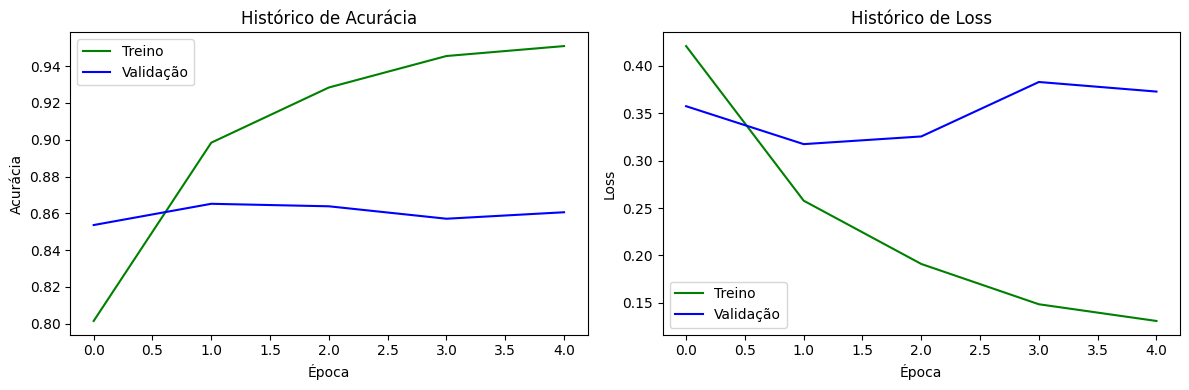

In [22]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Treino", color="green")
plt.plot(history.history["val_accuracy"], label="Validação", color="blue")
plt.title("Histórico de Acurácia")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Treino", color="green")
plt.plot(history.history["val_loss"], label="Validação", color="blue")
plt.title("Histórico de Loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPerda (Loss) no teste: {loss:.4f}")
print(f"Acurácia final no teste: {accuracy:.4f}")


Perda (Loss) no teste: 0.3727
Acurácia final no teste: 0.8606
